In [1]:
from pyrosm import OSM, get_data
import geopandas as gpd
import pandas as pd
import networkx as nx
import osmnx as ox
import pathlib
import pandas
from itertools import product
import matplotlib.pyplot as plt
import numpy
from matplotlib.colors import LinearSegmentedColormap

In [2]:
NOTEBOOK_PATH = pathlib.Path().resolve()
DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT = NOTEBOOK_PATH / "outputs"


In [3]:
Place_name = "Duisburg, North Rhine-Westphalia, Germany"

G = ox.graph_from_place(Place_name, network_type="walk", simplify=True)

In [4]:
G_projected = ox.project_graph(G)
G_projected

In [5]:
nodes, edges = ox.graph_to_gdfs(G_projected)
print(f"Nodes: {len(nodes):,}")
print(f"Edges: {len(edges):,}")

nodes.crs

Nodes: 43,751
Edges: 120,604


<Projected CRS: EPSG:32632>
Name: WGS 84 / UTM zone 32N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 6°E and 12°E, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Austria. Cameroon. Denmark. Equatorial Guinea. France. Gabon. Germany. Italy. Libya. Liechtenstein. Monaco. Netherlands. Niger. Nigeria. Norway. Sao Tome and Principe. Svalbard. Sweden. Switzerland. Tunisia. Vatican City State.
- bounds: (6.0, 0.0, 12.0, 84.0)
Coordinate Operation:
- name: UTM zone 32N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [6]:
# Check the coordinate reference system and geometry types
print("Nodes CRS:", nodes.crs)
print("Edges CRS:", edges.crs)

print("\nNode geometry types:")
print(nodes.geometry.geom_type.value_counts())

print("\nEdge geometry types:")
print(edges.geometry.geom_type.value_counts())

Nodes CRS: EPSG:32632
Edges CRS: EPSG:32632

Node geometry types:
Point    43751
Name: count, dtype: int64

Edge geometry types:
LineString    120604
Name: count, dtype: int64


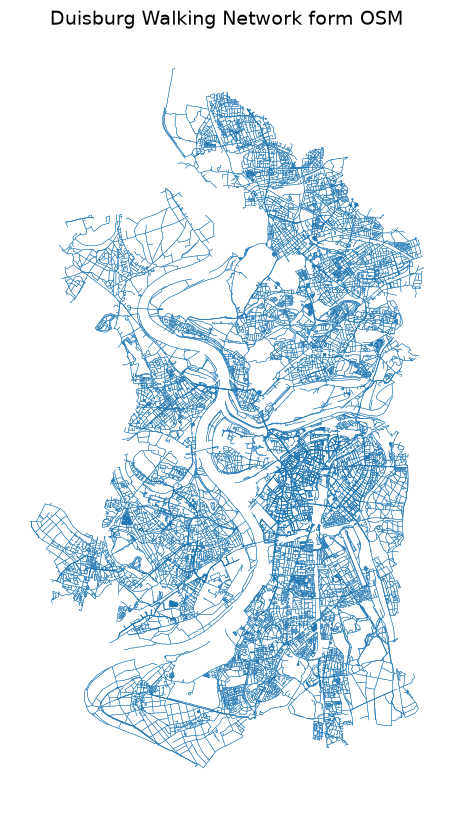

In [7]:
fig, ax = plt.subplots(figsize=(10,10))
edges.plot(ax=ax,linewidth=0.3) 
ax.set_title("Duisburg Walking Network form OSM", fontsize = 14)
ax.axis("off")

output_name = OUTPUT / "Duisburg_walking_network_osm.png"
plt.savefig(output_name, bbox_inches = "tight")
plt.show()

In [8]:
duisburg_boundary = ox.geocode_to_gdf(Place_name)
duisburg_boundary = duisburg_boundary.geometry.iloc[0]
osm = OSM(get_data("Duisburg", directory= DIRECTORY), bounding_box= duisburg_boundary)

residential_list_buildings = {"building":[
    "apartments", "barracks", "bungalow", "detached", "annexe", "dormitory", "hotel", "house", "residential", "semidetached_house", "house", "terrace"
]}

building_duisburg = osm.get_buildings(custom_filter=residential_list_buildings)

# print(f"Buildings in Duisburg: {len(building_duisburg):,}")
# building_duisburg.head()

supermarket = {"shop" : ["supermarket"]}


supermarket_duisburg = osm.get_pois(custom_filter = supermarket)

edeka_mask = supermarket_duisburg["name"].str.lower().str.startswith("edeka", na=False)
aldi_mask = supermarket_duisburg["name"].str.lower().str.startswith("aldi", na=False)
rewe_mask = supermarket_duisburg["name"].str.lower().str.startswith("rewe", na=False)
penny_mask = supermarket_duisburg["name"].str.lower().str.startswith("penny", na=False)
netto_mask = supermarket_duisburg["name"].str.lower().str.startswith("netto", na=False)
lidl_mask = supermarket_duisburg["name"].str.lower().str.startswith("lidl", na=False)

supermarket_duisburg.loc[edeka_mask, "name"] = "Edeka"
supermarket_duisburg.loc[aldi_mask, "name"] = "Aldi"
supermarket_duisburg.loc[rewe_mask, "name"] = "Rewe"
supermarket_duisburg.loc[penny_mask, "name"] = "Penny"
supermarket_duisburg.loc[netto_mask, "name"] = "Netto"
supermarket_duisburg.loc[lidl_mask, "name"] = "Lidl"

In [9]:
duisburg_boundary = ox.geocode_to_gdf(Place_name)
duisburg_boundary

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((6.62563 51.41097, 6.62821 51.40626, ...",6.625631,51.333383,6.830251,51.560069,428510021,relation,62456,51.434999,6.759562,boundary,administrative,12,0.663956,city,Duisburg,"Duisburg, North Rhine-Westphalia, Germany"


In [10]:
duisburg_boundary

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((6.62563 51.41097, 6.62821 51.40626, ...",6.625631,51.333383,6.830251,51.560069,428510021,relation,62456,51.434999,6.759562,boundary,administrative,12,0.663956,city,Duisburg,"Duisburg, North Rhine-Westphalia, Germany"


In [11]:
# building_duisburg.head()
print(building_duisburg.geometry.geom_type.value_counts())
print(supermarket_duisburg.geometry.geom_type.value_counts())
building_duisburg.head(5)

Polygon    41948
Name: count, dtype: int64
Polygon    80
Point      71
Name: count, dtype: int64


,addr:city,addr:country,addr:housenumber,addr:housename,addr:postcode,addr:place,addr:street,email,name,opening_hours,...,shop,source,start_date,id,timestamp,version,tags,osm_type,geometry,changeset
0,Duisburg,DE,2,NaN,47051,NaN,Opernplatz,info@wyndhamduisburg.com,Wyndham Duisburger Hof Hotel,NaN,...,NaN,NaN,1927,25071786,1774980915,16,"{""architect"":""Arthur Pfeifer, Hans Gro\u00DFma...",way,"POLYGON ((6.77155 51.43494, 6.77151 51.43485, ...",NaN
1,Duisburg,NaN,"15,17,19",NaN,47051,NaN,Königstraße,NaN,Commerzbank,"Fr 10:00-14:00; Mo,We 10:00-13:00,14:00-16:00;...",...,NaN,photography,NaN,25092209,1780839489,17,"{""atm"":""yes"",""brand"":""Commerzbank"",""brand:wiki...",way,"POLYGON ((6.76678 51.43346, 6.76698 51.43342, ...",NaN
2,Duisburg,DE,243,NaN,47228,NaN,Römerstraße,NaN,NaN,NaN,...,NaN,NaN,NaN,25308429,1674400698,8,"{""roof:levels"":""1"",""roof:shape"":""gabled""}",way,"POLYGON ((6.66733 51.42631, 6.66737 51.42625, ...",NaN
3,Duisburg,DE,249,NaN,47228,NaN,Römerstraße,NaN,NaN,NaN,...,NaN,NaN,NaN,25308430,1674400699,8,"{""roof:levels"":""1"",""roof:shape"":""gabled""}",way,"POLYGON ((6.66722 51.42647, 6.66739 51.42652, ...",NaN
4,Duisburg,DE,257,NaN,47228,NaN,Römerstraße,NaN,NaN,NaN,...,NaN,NaN,NaN,25308748,1674400697,8,"{""roof:shape"":""flat""}",way,"POLYGON ((6.66783 51.42695, 6.66784 51.42692, ...",NaN


In [12]:
building_duisburg_point = building_duisburg.copy()
supermarket_duisburg_point = supermarket_duisburg.copy()

building_duisburg_point["geometry"] = building_duisburg_point.geometry.representative_point()
supermarket_duisburg_point["geometry"] = supermarket_duisburg_point.geometry.representative_point()
# building_duisburg_point = building_duisburg_point.set_crs(building_duisburg.crs)

building_duisburg_point = building_duisburg_point.to_crs(nodes.crs)
supermarket_duisburg_point = supermarket_duisburg_point.to_crs(nodes.crs)
print(building_duisburg_point.geometry.geom_type.value_counts())
print(supermarket_duisburg_point.geometry.geom_type.value_counts())
print(building_duisburg_point.columns)


Point    41948
Name: count, dtype: int64
Point    151
Name: count, dtype: int64
Index(['addr:city', 'addr:country', 'addr:housenumber', 'addr:housename',
       'addr:postcode', 'addr:place', 'addr:street', 'email', 'name',
       'opening_hours', 'operator', 'phone', 'ref', 'visible', 'website',
       'building', 'amenity', 'building:flats', 'building:levels',
       'building:material', 'building:use', 'craft', 'height',
       'internet_access', 'office', 'shop', 'source', 'start_date', 'id',
       'timestamp', 'version', 'tags', 'osm_type', 'geometry', 'changeset'],
      dtype='str')


In [13]:
building_duisburg_useful_col = [
    "id",
    "addr:housenumber",
    "addr:postcode",
    "addr:street",
    "geometry"
]

supermarket_duisburg_useful_col = [
    "id",
    "name",
    "geometry"
]

building_duisburg_point_clean = building_duisburg_point[building_duisburg_useful_col].copy()
supermarket_duisburg_point_clean = supermarket_duisburg_point[supermarket_duisburg_useful_col].copy()

print(building_duisburg_point_clean.columns)
print(supermarket_duisburg_point_clean.columns)

Index(['id', 'addr:housenumber', 'addr:postcode', 'addr:street', 'geometry'], dtype='str')
Index(['id', 'name', 'geometry'], dtype='str')


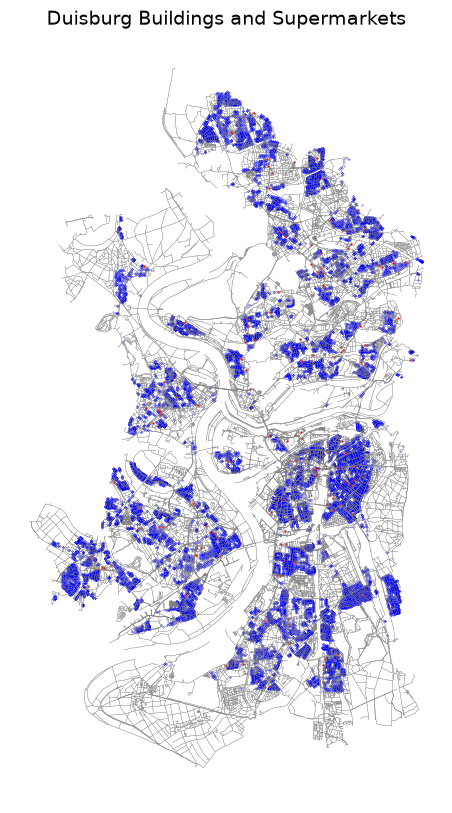

In [14]:
fig, ax = plt.subplots(figsize=(10,10))

edges.plot(ax = ax, color= "gray", linewidth=0.2)
building_duisburg_point_clean.plot(ax = ax, color= "blue", markersize = 0.05)
supermarket_duisburg_point_clean.plot(ax=ax, color = "red", markersize = 0.5)
ax.axis("off")

ax.set_title("Duisburg Buildings and Supermarkets", fontsize = 14)
output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")


In [15]:
G_access = ox.convert.to_undirected(G_projected)

building_duisburg_point_clean = building_duisburg_point_clean.copy()
building_duisburg_point_clean["nearest_node"] = ox.distance.nearest_nodes(
    G_access, 
    X= building_duisburg_point_clean.geometry.x,
    Y= building_duisburg_point_clean.geometry.y
    )

supermarket_duisburg_point_clean = supermarket_duisburg_point_clean.copy()
supermarket_duisburg_point_clean["nearest_node"] = ox.distance.nearest_nodes(
    G_access,
    X = supermarket_duisburg_point_clean.geometry.x,
    Y = supermarket_duisburg_point_clean.geometry.y
)

"""
Hier noch verfeinern was source was target ist und ob beide sources sind
"""

source_nodes_buildings = building_duisburg_point_clean["nearest_node"].tolist()
source_nodes_supermarket = supermarket_duisburg_point_clean["nearest_node"].tolist()


In [16]:
# source_nodes_supermarket_name = []

# for i, j in zip(supermarket_duisburg_point_clean['name'],
#                 supermarket_duisburg_point_clean['nearest_node']):
#     source_nodes_supermarket_name.append({i: j})

# source_nodes_supermarket_name

In [17]:
print(len(supermarket_duisburg_point_clean))
print(len(building_duisburg_point_clean))
print(len(source_nodes_supermarket))
print(source_nodes_supermarket)


supermarket_duisburg_point_clean.head()



151
41948
151
[3168251749, 1345797225, 2334849759, 271942248, 458884175, 2174751161, 8444691656, 2470892582, 2132267156, 3467455371, 6448462399, 1102104465, 405245374, 3314277488, 271239528, 392121520, 7043412583, 3643380176, 13978516663, 2113409244, 2411791047, 2657478767, 1616002227, 1634321417, 2021572651, 1580017381, 307699698, 1039170055, 6804721327, 1623448678, 2427699327, 7292342394, 7102134248, 7045716653, 6634164843, 2377767620, 6800282249, 1630565196, 263681364, 1634314566, 288188460, 7852510063, 7037814305, 151060269, 2426456679, 315340184, 273095402, 288181000, 1654759797, 1963455738, 11239957912, 1100165819, 1037431677, 1629978657, 1651919072, 2425311817, 13116060758, 11136134194, 1710182661, 10559350265, 2377767860, 2427699327, 33597248, 1338125749, 271017586, 4992349510, 1720439713, 6011250006, 1435781007, 196567880, 11865362093, 307732806, 364783184, 6191172979, 14021071436, 527875585, 13587131103, 2174765065, 458758307, 322041624, 2446218753, 3053886914, 458872596, 458

,id,name,geometry,nearest_node
0,209226489,Netto,POINT (346761.782 5695702.479),3168251749
1,214043979,Netto,POINT (345341.064 5692624.358),1345797225
2,243457549,Edeka,POINT (343284.144 5692456.453),2334849759
3,271942242,Aldi,POINT (345410.199 5693449.226),271942248
4,365346509,Edeka,POINT (340715.217 5698989.183),458884175


In [18]:
distance_to_supermarket = nx.multi_source_dijkstra_path_length(
    G_access,
    source_nodes_supermarket,
    weight = "length"
)
distance_to_supermarket2 = nx.multi_source_dijkstra_path(
    G_access,
    source_nodes_supermarket,
    weight = "length"
)
nodes_access_supermarket = nodes.copy()
nodes_access_supermarket["distance_to_supermarket"] = nodes_access_supermarket.index.map(distance_to_supermarket)
nodes_access_supermarket["distance_to_supermarket"].describe()
# nodes_access_supermarket["distance_to_supermarket"].eq(0).sum() ## 150 nodes haben eine distanz von 0 metern -> das sind die supermärkte

count    43751.000000
mean       862.705790
std        707.147547
min          0.000000
25%        409.310224
50%        704.717679
75%       1075.187730
max       6535.181113
Name: distance_to_supermarket, dtype: float64

In [19]:
# 1) von jedem existierenden Node die kürzesten Distanzen UND Pfade zu jedem Supermarkt berechnen
dist, paths = nx.multi_source_dijkstra(G_access, source_nodes_supermarket, weight="length")
len(paths)
# list(paths.items())[:30]


node_to_name = (supermarket_duisburg_point_clean.drop_duplicates("nearest_node").set_index("nearest_node")["name"].to_dict())

list(paths.items())
nearest_node = {node:path[0] for node, path in paths.items()}

building_duisburg_point_clean["dist_to_supermarket"] = building_duisburg_point_clean["nearest_node"].map(dist)
building_duisburg_point_clean["nearest_node_supermarket"] = building_duisburg_point_clean["nearest_node"].map(nearest_node)
building_duisburg_point_clean["name_supermarket"] = building_duisburg_point_clean["nearest_node_supermarket"].map(node_to_name)
building_duisburg_point_clean.head()

,id,addr:housenumber,addr:postcode,addr:street,geometry,nearest_node,dist_to_supermarket,nearest_node_supermarket,name_supermarket
0,25071786,2,47051,Opernplatz,POINT (345115.354 5700505.684),563357000,466.945573,2377768059,Aldi
1,25092209,"15,17,19",47051,Königstraße,POINT (344788.732 5700405.103),1118989441,58.544058,273095402,Penny
2,25308429,243,47228,Römerstraße,POINT (337839.001 5699813.689),275672242,84.552512,271239528,Rewe
3,25308430,249,47228,Römerstraße,POINT (337829.717 5699838.833),275672245,128.371821,271239528,Rewe
4,25308748,257,47228,Römerstraße,POINT (337872.75 5699878.829),85471036,193.069693,271239528,Rewe


In [20]:
node_to_name

{3168251749: 'Netto',
 1345797225: 'Netto',
 2334849759: 'Edeka',
 271942248: 'Aldi',
 458884175: 'Edeka',
 2174751161: 'Netto',
 8444691656: 'Edeka',
 2470892582: 'Burc Frischmarkt',
 2132267156: 'Netto',
 3467455371: 'Netto',
 6448462399: 'Norma',
 1102104465: 'Edeka',
 405245374: 'Edeka',
 3314277488: 'Penny',
 271239528: 'Rewe',
 392121520: 'Rewe',
 7043412583: 'Penny',
 3643380176: 'Kaufland',
 13978516663: 'Penny',
 2113409244: 'Depo',
 2411791047: 'Netto',
 2657478767: 'Pro Biomarkt',
 1616002227: 'Penny',
 1634321417: 'Penny',
 2021572651: 'Globus',
 1580017381: 'Yasmeen Frischmarkt',
 307699698: 'Bereket Market',
 1039170055: 'Esma Supermarkt',
 6804721327: 'Hofladen Enninghorst',
 1623448678: 'Pro Biomarkt',
 2427699327: 'Go Asia',
 7292342394: 'Edeka',
 7102134248: 'Netto',
 7045716653: 'Edeka',
 6634164843: 'Sila Market',
 2377767620: "Ming's Asia Markt",
 6800282249: 'Edeka',
 1630565196: 'Netto',
 263681364: 'Netto',
 1634314566: 'Aldi',
 288188460: 'Rewe',
 7852510063: '

In [21]:
# print(building_duisburg_point_clean["dist_to_supermarket"].describe())
bins = [0, 500, 1000, 1500, float("inf")]
labels = ["0–500 m", "500-1000 m", "1000-1500 m", "1500+ m"]

building_duisburg_point_clean["dist_to_supermarket_cut"] = pd.cut(
    building_duisburg_point_clean["dist_to_supermarket"],
    bins = bins,
    labels= labels,
    include_lowest=True
)

label_summary = building_duisburg_point_clean["dist_to_supermarket_cut"].value_counts().sort_index()
label_share = (label_summary / len(building_duisburg_point_clean) * 100).round(1)
print(sum(label_summary))

pd.DataFrame({
    "Count of Buildings": label_summary,
    "Share of Percent": label_share
})
# building_duisburg_point_clean.head()
# building_duisburg_point_clean["accessibility_supermarket"] = pd.cut(building_duisburg_point_clean["name_supermarket"], bins = bins, include_lowest=True)

# bins = building_duisburg_point_clean["name_supermarket"].group()
# print(len(building_duisburg_point_clean))

41948


,Count of Buildings,Share of Percent
dist_to_supermarket_cut,,
0–500 m,18295,43.6
500-1000 m,16566,39.5
1000-1500 m,4005,9.5
1500+ m,3082,7.3


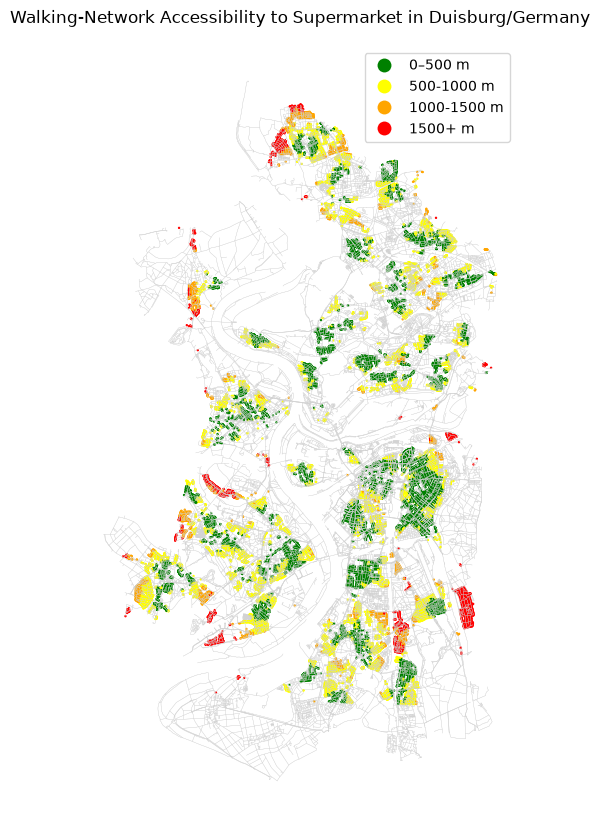

In [47]:
fig, ax = plt.subplots(figsize = (10,10))
cmap = LinearSegmentedColormap.from_list("gyor", ["green", "yellow", "orange", "red"])

edges.plot(ax=ax,linewidth=0.2, color = "lightgray") 

building_duisburg_point_clean.plot(ax = ax, column = "dist_to_supermarket_cut", cmap= cmap, markersize = 0.5, legend = True)
ax.set_title("Walking-Network Accessibility to Supermarket in Duisburg/Germany")
ax.set_axis_off()

output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000_nearest_distance.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")

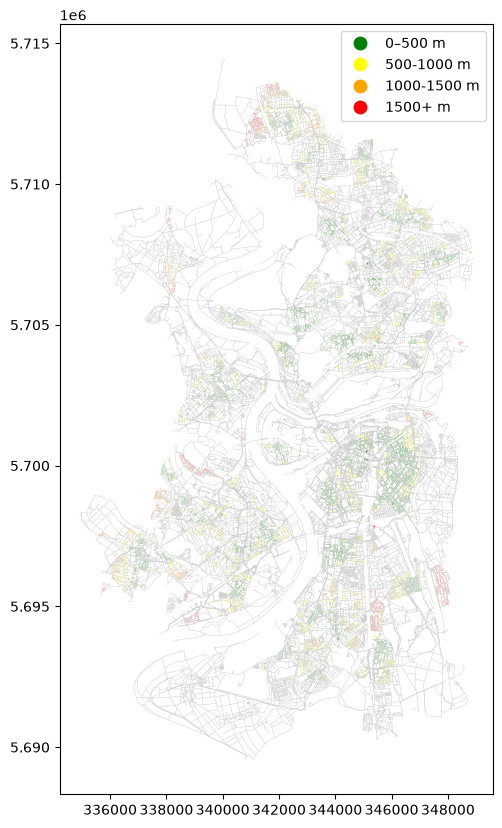

In [23]:
"""
einen Weg finden die building_duisburg.geometry = polygon auf building_duisburg_point_clean.geometry = point zu übertragen die zu ersetzen

"""

building_duisburg_endproduct = building_duisburg_point_clean.copy()
building_duisburg_endproduct["geometry"] = building_duisburg.geometry.to_crs(nodes.crs)


fig, ax = plt.subplots(figsize = (10,10))
cmap = LinearSegmentedColormap.from_list("gyor", ["green", "yellow", "orange", "red"])

edges.plot(ax=ax,linewidth=0.2, color = "lightgray") 

building_duisburg_endproduct.plot(ax = ax, column = "dist_to_supermarket_cut", cmap= cmap, markersize = 1, legend = True)
ax.set_axis_off

output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000_nearest_distance_GPOLYGON.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")

In [24]:
"""
Stadtteile hinzufügen um ein Ranking zu erstellen -> check
Zusätzlich zu length -> Minuten 
skript so umbauen dass jede stadt hinzugefügt werden kann.
"""

'\nStadtteile hinzufügen um ein Ranking zu erstellen -> check\nZusätzlich zu length -> Minuten \nskript so umbauen dass jede stadt hinzugefügt werden kann.\n'

In [63]:
# stadtteile_duisburg = osm.get_boundaries(custom_filter = {"admin_level" : ["9"]})#.to_crs(nodes.crs)
Place_name = "Duisburg, North Rhine-Westphalia, Germany"
admin_level_9= ox.features_from_place(
    Place_name,
    tags={"admin_level" : "9"},
)
# stadtteile_duisburg = ox.features_from_place(Place_name, tags ={ "admin_level": "9"},)
# stadtteile_duisburg = osm.get_boundaries(boundary_type= "administrative").to_crs(nodes.crs)
# stadtteile_duisburg = stadtteile_duisburg.drop(0) ## Delete averbruch. By mistake taken into account
stadtteile_duisburg = [
    "Rheinhausen",
    "Homberg/Ruhrort/Baerl",
    "Walsum",
    "Hamborn",
    "Meiderich/Beeck",
    "Duisburg-Mitte",
    "Duisburg-Süd"
]

admin_level_9= admin_level_9[admin_level_9["name"].isin(stadtteile_duisburg)].to_crs(nodes.crs)

admin_level_9

# duisburg_boundary_test = ox.geocode_to_gdf(Place_name)


geometry  \
element  id                                                           
relation 1350280  POLYGON ((335044.472 5697648.038, 335040.342 5...   
         1350346  POLYGON ((335365.377 5708489.831, 335624.492 5...   
         1357886  POLYGON ((339634.222 5714646.222, 339737.664 5...   
         1357922  POLYGON ((341308.636 5707463.142, 341701.652 5...   
         1357936  POLYGON ((340145.807 5704702.906, 339776.03 57...   
         1357946  POLYGON ((340961.561 5701100.463, 341149.98 57...   
         1357947  POLYGON ((336974.909 5691342.308, 336877.609 5...   

                 admin_level        boundary source source:ref  \
element  id                                                      
relation 1350280           9  administrative    NaN        NaN   
         1350346           9  administrative    NaN        NaN   
         1357886           9  administrative    NaN        NaN   
         1357922           9  administrative    NaN        NaN   
         1357936           9  administrative    NaN        NaN   
         1357946           9  administrative    NaN        NaN   
         1357947           9  administrative    NaN        NaN   

                                   name      type population  ref  \
element  id                                                         
relation 1350280            Rheinhausen  boundary        NaN  600   
         1350346  Homberg/Ruhrort/Baerl  boundary        NaN  400   
         1357886                 Walsum  boundary        NaN  100   
         1357922                Hamborn  boundary        NaN  200   
         1357936        Meiderich/Beeck  boundary        NaN  300   
         1357946         Duisburg-Mitte  boundary        NaN  500   
         1357947           Duisburg-Süd  boundary        NaN  700   

                 source:population  wikidata  \
element  id                                    
relation 1350280               NaN   Q469928   
         1350346               NaN   Q881325   
         1357886               NaN   Q449632   
         1357922               NaN   Q512233   
         1357936               NaN  Q5764545   
         1357946               NaN   Q317314   
         1357947               NaN   Q884445   

                                          wikipedia  name:prefix FIXME  \
element  id                                                              
relation 1350280            de:Duisburg-Rheinhausen          NaN   NaN   
         1350346  de:Duisburg-Homberg/Ruhrort/Baerl  Stadtbezirk   NaN   
         1357886                 de:Duisburg-Walsum  Stadtbezirk   NaN   
         1357922                         de:Hamborn  Stadtbezirk   NaN   
         1357936        de:Duisburg-Meiderich/Beeck  Stadtbezirk   NaN   
         1357946                  de:Duisburg-Mitte  Stadtbezirk   NaN   
         1357947                    de:Duisburg-Süd  Stadtbezirk   NaN   

                 alt_name  
element  id                
relation 1350280      NaN  
         1350346      NaN  
         1357886      NaN  
         1357922      NaN  
         1357936      NaN  
         1357946      NaN  
         1357947      NaN

In [26]:
print(admin_level_9.columns)
print(building_duisburg_point_clean.columns)
dist_supermarket_district = gpd.sjoin(building_duisburg_point_clean, admin_level_9, how = "left" )
dist_supermarket_district = dist_supermarket_district[["name", "geometry", "dist_to_supermarket", "name_supermarket"]]

dist_supermarket_district

Index(['geometry', 'admin_level', 'boundary', 'source', 'source:ref', 'name',
       'type', 'population', 'ref', 'source:population', 'wikidata',
       'wikipedia', 'name:prefix', 'FIXME', 'alt_name'],
      dtype='str')
Index(['id', 'addr:housenumber', 'addr:postcode', 'addr:street', 'geometry',
       'nearest_node', 'dist_to_supermarket', 'nearest_node_supermarket',
       'name_supermarket', 'dist_to_supermarket_cut'],
      dtype='str')


,name,geometry,dist_to_supermarket,name_supermarket
0,Duisburg-Mitte,POINT (345115.354 5700505.684),466.945573,Aldi
1,Duisburg-Mitte,POINT (344788.732 5700405.103),58.544058,Penny
2,Rheinhausen,POINT (337839.001 5699813.689),84.552512,Rewe
3,Rheinhausen,POINT (337829.717 5699838.833),128.371821,Rewe
4,Rheinhausen,POINT (337872.75 5699878.829),193.069693,Rewe
...,...,...,...,...
41943,Rheinhausen,POINT (340726.013 5695579.973),290.280715,Penny
41944,Duisburg-Mitte,POINT (346150.408 5701191.196),586.956042,Aldi
41945,Rheinhausen,POINT (339286.929 5698454.799),417.932678,Aldi
41946,Duisburg-Mitte,POINT (346555.87 5700455.211),300.934521,Burc Frischmarkt


In [64]:

dist_supermarket_district = gpd.sjoin(building_duisburg_point_clean, admin_level_9, how = "left" )

dist_supermarket_district = dist_supermarket_district[["name", "geometry", "dist_to_supermarket", "name_supermarket"]]

print(dist_supermarket_district.columns)
print(len(dist_supermarket_district))
dist_supermarket_district_mean = dist_supermarket_district.groupby("name")["dist_to_supermarket"].mean().sort_values()
dist_supermarket_district_mean
admin_level_9 = admin_level_9.merge(
    dist_supermarket_district_mean,
    left_on="name",  
    right_index=True,  
    how="left",  
)
print(dist_supermarket_district_mean)
# # admin_level_9["dist_to_supermarket"] = admin_level_9["dist_to_supermarket"].round(0).astype(int)

Index(['name', 'geometry', 'dist_to_supermarket', 'name_supermarket'], dtype='str')
41948
name
Duisburg-Mitte           464.423872
Meiderich/Beeck          494.320245
Hamborn                  578.256871
Homberg/Ruhrort/Baerl    747.236852
Rheinhausen              771.195096
Walsum                   829.131013
Duisburg-Süd             918.111419
Name: dist_to_supermarket, dtype: float64


In [65]:
admin_level_9["dist_to_supermarket"] = admin_level_9["dist_to_supermarket"].round(0).astype(int)
admin_level_9

geometry  \
element  id                                                           
relation 1350280  POLYGON ((335044.472 5697648.038, 335040.342 5...   
         1350346  POLYGON ((335365.377 5708489.831, 335624.492 5...   
         1357886  POLYGON ((339634.222 5714646.222, 339737.664 5...   
         1357922  POLYGON ((341308.636 5707463.142, 341701.652 5...   
         1357936  POLYGON ((340145.807 5704702.906, 339776.03 57...   
         1357946  POLYGON ((340961.561 5701100.463, 341149.98 57...   
         1357947  POLYGON ((336974.909 5691342.308, 336877.609 5...   

                 admin_level        boundary source source:ref  \
element  id                                                      
relation 1350280           9  administrative    NaN        NaN   
         1350346           9  administrative    NaN        NaN   
         1357886           9  administrative    NaN        NaN   
         1357922           9  administrative    NaN        NaN   
         1357936           9  administrative    NaN        NaN   
         1357946           9  administrative    NaN        NaN   
         1357947           9  administrative    NaN        NaN   

                                   name      type population  ref  \
element  id                                                         
relation 1350280            Rheinhausen  boundary        NaN  600   
         1350346  Homberg/Ruhrort/Baerl  boundary        NaN  400   
         1357886                 Walsum  boundary        NaN  100   
         1357922                Hamborn  boundary        NaN  200   
         1357936        Meiderich/Beeck  boundary        NaN  300   
         1357946         Duisburg-Mitte  boundary        NaN  500   
         1357947           Duisburg-Süd  boundary        NaN  700   

                 source:population  wikidata  \
element  id                                    
relation 1350280               NaN   Q469928   
         1350346               NaN   Q881325   
         1357886               NaN   Q449632   
         1357922               NaN   Q512233   
         1357936               NaN  Q5764545   
         1357946               NaN   Q317314   
         1357947               NaN   Q884445   

                                          wikipedia  name:prefix FIXME  \
element  id                                                              
relation 1350280            de:Duisburg-Rheinhausen          NaN   NaN   
         1350346  de:Duisburg-Homberg/Ruhrort/Baerl  Stadtbezirk   NaN   
         1357886                 de:Duisburg-Walsum  Stadtbezirk   NaN   
         1357922                         de:Hamborn  Stadtbezirk   NaN   
         1357936        de:Duisburg-Meiderich/Beeck  Stadtbezirk   NaN   
         1357946                  de:Duisburg-Mitte  Stadtbezirk   NaN   
         1357947                    de:Duisburg-Süd  Stadtbezirk   NaN   

                 alt_name  dist_to_supermarket  
element  id                                     
relation 1350280      NaN                  771  
         1350346      NaN                  747  
         1357886      NaN                  829  
         1357922      NaN                  578  
         1357936      NaN                  494  
         1357946      NaN                  464  
         1357947      NaN                  918

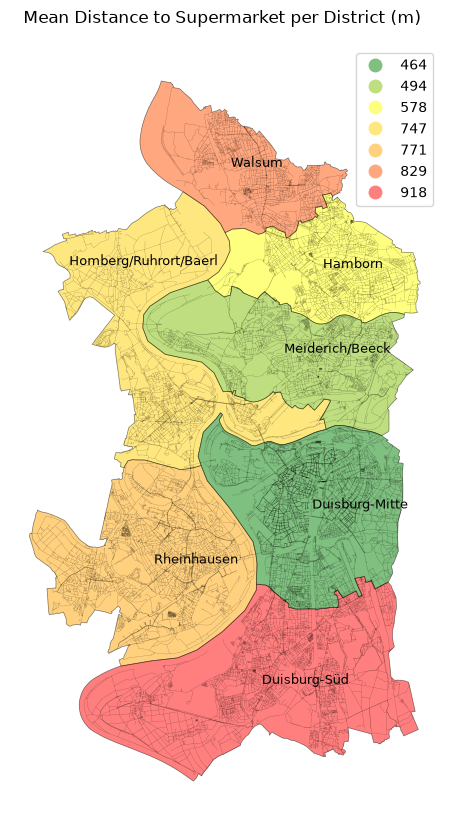

In [91]:
fig, ax = plt.subplots(figsize = (10,10))

cmap = LinearSegmentedColormap.from_list("gyor", ["green", "yellow", "orange", "red"])

admin_level_9.plot(ax=ax, column= "dist_to_supermarket", categorical=True, edgecolor= "black", linewidth=0.5, cmap=cmap, alpha = 0.5, legend = True)

def change_pos_HomRuhBae (x):
    if x["name"] == "Homberg/Ruhrort/Baerl":
        ax.annotate(
            text = x["name"],
            xy = x.geometry.centroid.coords[0],
            xytext = (339000, 5708000),
            fontsize = 9,
            ha = "center"
        )
    
    else:
        ax.annotate( 
        text = x["name"],
        xy = x.geometry.centroid.coords[0],
        fontsize = 9
        )

admin_level_9.apply(change_pos_HomRuhBae, axis = 1)

# admin_level_9.apply(lambda x: ax.annotate(text=x["name"], xy=x.geometry.centroid.coords[0], ha = "center", fontsize = 9), axis = 1)
edges.plot(ax=ax,linewidth=0.2, color = "black", alpha = 0.2) 
ax.set_title("Mean Distance to Supermarket per District (m) ")


legend_kwds={'title': 'Average distance to supermarket (m)'}
# ax.legend()

# building_duisburg_endproduct.plot(ax = ax, column = "dist_to_supermarket_cut", cmap= cmap, markersize = 1, legend = True)

ax.set_axis_off()

output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000_nearest_distance_cityDistricts.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")